# Option Pricing: Black-Scholes and Monte Carlo

This project prices European call and put options with the Black-Scholes formula, simulates stock prices with a geometric Brownian motion, prices the same options by Monte Carlo simulation and studies the Greeks (delta, gamma, vega). Status: complete.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

## Parameters

An at-the-money option on a stock trading at 100, with a maturity of one year.

In [2]:
S0 = 100      # current stock price
K = 100       # strike price
T = 1         # maturity in years
r = 0.03      # risk-free rate (annual, continuously compounded)
sigma = 0.20  # volatility (annual)

## Step 1: Payoffs at maturity

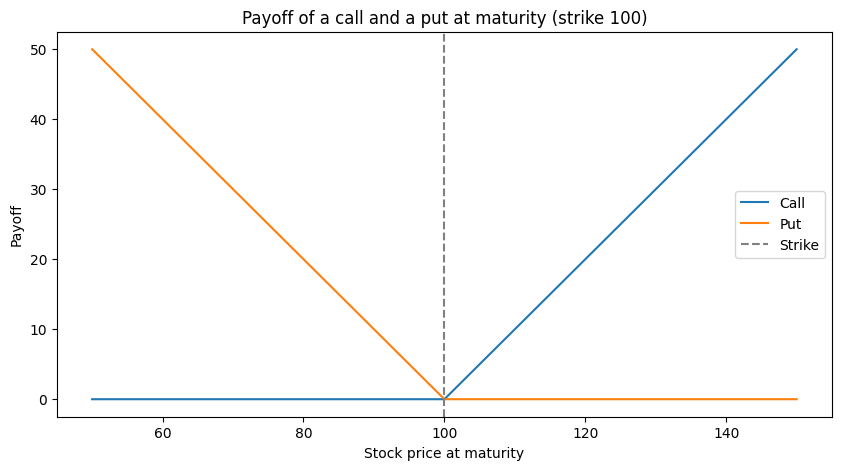

In [3]:
# Possible stock prices at maturity
S_T = np.linspace(50, 150, 101)

call_payoff = np.maximum(S_T - K, 0)   # the call pays S_T - K if S_T > K, otherwise 0
put_payoff = np.maximum(K - S_T, 0)    # the put pays K - S_T if S_T < K, otherwise 0

plt.figure(figsize=(10, 5))
plt.plot(S_T, call_payoff, label="Call")
plt.plot(S_T, put_payoff, label="Put")
plt.axvline(K, color="grey", linestyle="--", label="Strike")
plt.xlabel("Stock price at maturity")
plt.ylabel("Payoff")
plt.title("Payoff of a call and a put at maturity (strike 100)")
plt.legend()
plt.show()

### Interpretation

The call pays off only if the stock ends above the strike, and the put only if it ends below. The loss of the buyer is limited to the premium paid, while the gain of the call is unlimited. This asymmetry is what gives value to volatility: a larger range of possible prices increases the expected payoff without increasing the maximum loss.

## Step 2: Black-Scholes formula

In [4]:
def bs_price(S, K, T, r, sigma, option="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

call_bs = bs_price(S0, K, T, r, sigma, "call")
put_bs = bs_price(S0, K, T, r, sigma, "put")

print("Call price:", round(call_bs, 4))
print("Put price:", round(put_bs, 4))

Call price: 9.4134
Put price: 6.458


In [5]:
# Put-call parity: C - P = S0 - K * exp(-rT)
left = call_bs - put_bs
right = S0 - K * np.exp(-r * T)
print("C - P:", round(left, 4))
print("S0 - K exp(-rT):", round(right, 4))

C - P: 2.9554
S0 - K exp(-rT): 2.9554


### Interpretation

The call is worth 9.41 and the put 6.46. The call is more expensive because the forward price of the stock (S0 exp(rT) = 103.05) is above the strike: with a 3% interest rate, the stock is expected to grow under the risk-neutral measure, which favours the call.

Put-call parity holds exactly (2.9554 on both sides). Buying a call and selling a put gives the same payoff as a forward contract (S_T - K), so both positions must have the same price today, otherwise an arbitrage would be possible.

## Step 3: Simulation of stock prices (geometric Brownian motion)

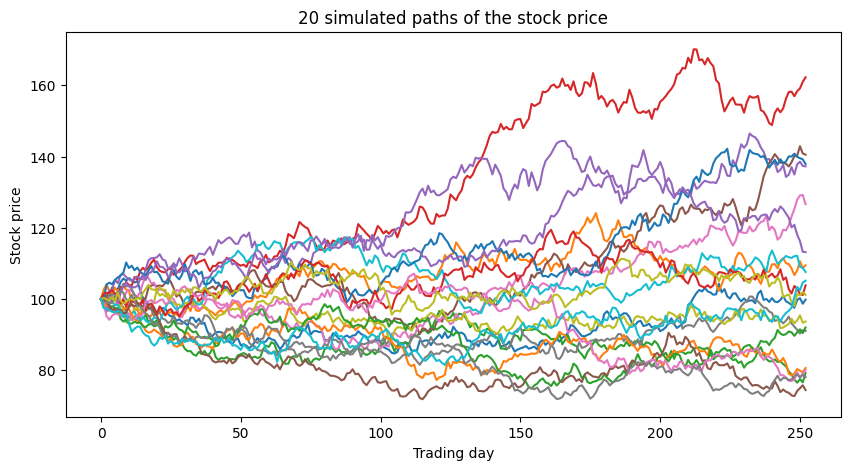

In [6]:
# Under the risk-neutral measure, the stock price follows dS = r S dt + sigma S dW
# Exact discretization: S(t+dt) = S(t) * exp((r - sigma^2 / 2) dt + sigma * sqrt(dt) * Z), Z ~ N(0, 1)

n_steps = 252        # one step per trading day
n_paths = 10000
dt = T / n_steps
np.random.seed(42)

Z = np.random.standard_normal((n_paths, n_steps))
log_returns = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
paths = S0 * np.exp(np.cumsum(log_returns, axis=1))
paths = np.hstack([np.full((n_paths, 1), S0), paths])   # add the starting price

plt.figure(figsize=(10, 5))
plt.plot(paths[:20].T)
plt.xlabel("Trading day")
plt.ylabel("Stock price")
plt.title("20 simulated paths of the stock price")
plt.show()

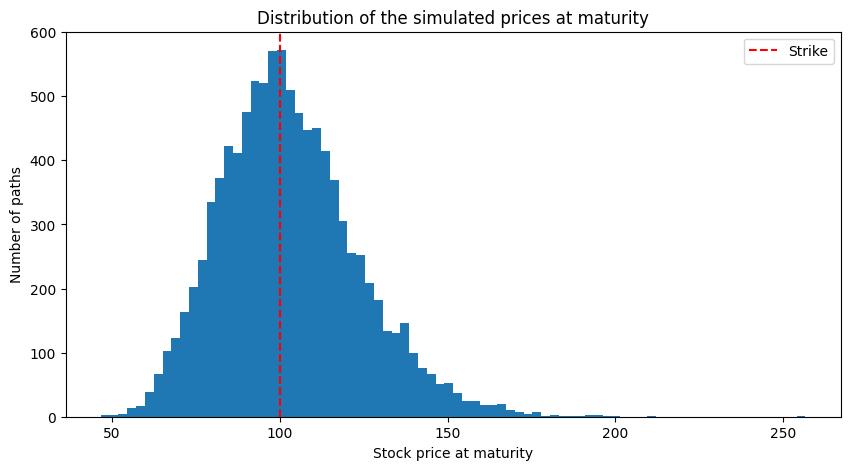

Mean of S_T: 102.8547
Expected value S0 * exp(rT): 103.0455
Discounted mean of S_T: 99.8149


In [7]:
S_T_sim = paths[:, -1]   # prices at maturity

plt.figure(figsize=(10, 5))
plt.hist(S_T_sim, bins=80)
plt.axvline(K, color="red", linestyle="--", label="Strike")
plt.xlabel("Stock price at maturity")
plt.ylabel("Number of paths")
plt.title("Distribution of the simulated prices at maturity")
plt.legend()
plt.show()

# The discounted stock price is a martingale: its expected value today is S0
print("Mean of S_T:", round(S_T_sim.mean(), 4))
print("Expected value S0 * exp(rT):", round(S0 * np.exp(r * T), 4))
print("Discounted mean of S_T:", round(np.exp(-r * T) * S_T_sim.mean(), 4))

### Interpretation

The simulated paths show the random evolution of the stock with a volatility of 20% per year. The distribution of prices at maturity is skewed to the right: the price cannot fall below zero but can rise without limit, which corresponds to the lognormal distribution of the model.

The mean of the simulated prices at maturity (102.85) is close to S0 exp(rT) = 103.05, and the discounted mean (99.81) is close to today's price of 100. Under the risk-neutral measure, the discounted stock price is a martingale: its expected future value, discounted at the risk-free rate, equals its current value. This is the foundation of option pricing. The small gap comes from the simulation error, about 0.2 with 10,000 paths.

## Step 4: Monte Carlo pricing

In [8]:
def mc_price(S0, K, T, r, sigma, n_sim, option="call"):
    Z = np.random.standard_normal(n_sim)
    S_T = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)   # one step is enough for a European option
    if option == "call":
        payoff = np.maximum(S_T - K, 0)
    else:
        payoff = np.maximum(K - S_T, 0)
    price = np.exp(-r * T) * payoff.mean()
    std_error = np.exp(-r * T) * payoff.std() / np.sqrt(n_sim)
    return price, std_error

np.random.seed(42)
call_mc, call_se = mc_price(S0, K, T, r, sigma, 100000, "call")
put_mc, put_se = mc_price(S0, K, T, r, sigma, 100000, "put")

results = pd.DataFrame({
    "Black-Scholes": [call_bs, put_bs],
    "Monte Carlo": [call_mc, put_mc],
    "Standard error": [call_se, put_se],
    "95% interval low": [call_mc - 1.96 * call_se, put_mc - 1.96 * put_se],
    "95% interval high": [call_mc + 1.96 * call_se, put_mc + 1.96 * put_se],
}, index=["Call", "Put"])
results.round(4)

,Black-Scholes,Monte Carlo,Standard error,95% interval low,95% interval high
Call,9.4134,9.4356,0.0447,9.3481,9.5231
Put,6.4580,6.4421,0.0296,6.3842,6.5001


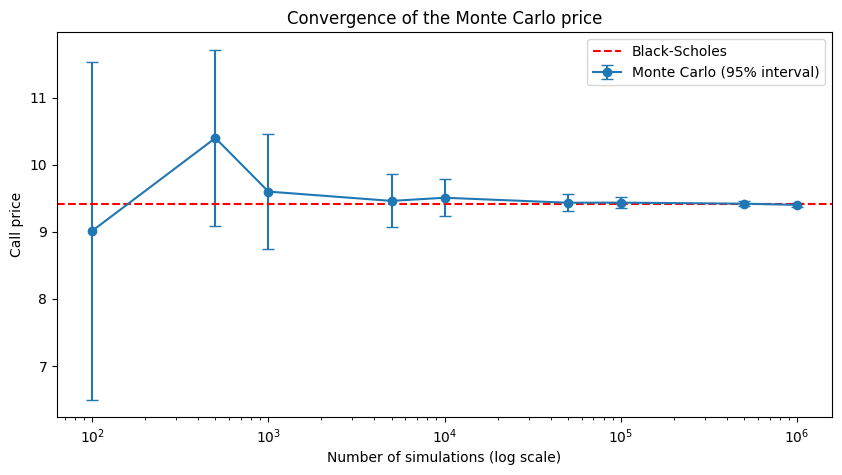

,Simulations,Price,Standard error
0,100,9.0125,1.2840
1,500,10.3958,0.6725
2,1000,9.5975,0.4397
3,5000,9.4585,0.2015
4,10000,9.5058,0.1417
5,50000,9.4312,0.0631
6,100000,9.4329,0.0446
7,500000,9.4169,0.0199
8,1000000,9.3997,0.0141


In [9]:
# Convergence: Monte Carlo price for an increasing number of simulations
np.random.seed(1)
sizes = [100, 500, 1000, 5000, 10000, 50000, 100000, 500000, 1000000]
mc_prices = []
mc_errors = []
for n_sim in sizes:
    price, se = mc_price(S0, K, T, r, sigma, n_sim, "call")
    mc_prices.append(price)
    mc_errors.append(se)

plt.figure(figsize=(10, 5))
plt.errorbar(sizes, mc_prices, yerr=1.96 * np.array(mc_errors), fmt="o-", capsize=4, label="Monte Carlo (95% interval)")
plt.axhline(call_bs, color="red", linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulations (log scale)")
plt.ylabel("Call price")
plt.title("Convergence of the Monte Carlo price")
plt.legend()
plt.show()

pd.DataFrame({"Simulations": sizes, "Price": mc_prices, "Standard error": mc_errors}).round(4)

### Interpretation

With 100,000 simulations, the Monte Carlo prices (9.44 for the call, 6.44 for the put) are within a few cents of the Black-Scholes prices, which fall inside the 95% confidence intervals.

The convergence chart shows that the standard error decreases with the square root of the number of simulations: going from 10,000 to 1,000,000 simulations divides the error by 10 (from 0.14 to 0.014). Monte Carlo is slower than a closed formula, but it is the method used when no formula exists, for example for path-dependent products such as autocalls.

## Step 5: The Greeks (delta, gamma, vega)

In [10]:
def bs_greeks(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    delta = norm.cdf(d1)                               # change in call price for a 1 change in the stock price
    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(T))    # change in delta for a 1 change in the stock price
    vega = S * norm.pdf(d1) * np.sqrt(T) / 100         # change in price for a 1 point increase in volatility
    return delta, gamma, vega

delta, gamma, vega = bs_greeks(S0, K, T, r, sigma)
print("Delta:", round(delta, 4))
print("Gamma:", round(gamma, 4))
print("Vega:", round(vega, 4))

Delta: 0.5987
Gamma: 0.0193
Vega: 0.3867


In [11]:
# Check the delta by "bump and reprice": move the stock price by a small amount and reprice
h = 0.01
delta_bump = (bs_price(S0 + h, K, T, r, sigma) - bs_price(S0 - h, K, T, r, sigma)) / (2 * h)
print("Delta (formula):", round(delta, 4))
print("Delta (bump and reprice):", round(delta_bump, 4))

Delta (formula): 0.5987
Delta (bump and reprice): 0.5987


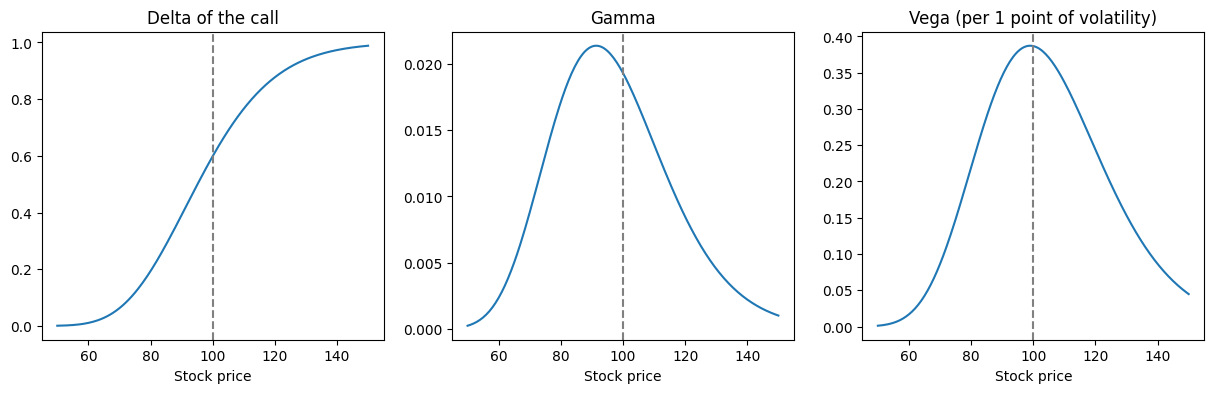

In [12]:
S_range = np.linspace(50, 150, 201)
deltas, gammas, vegas = bs_greeks(S_range, K, T, r, sigma)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(S_range, deltas)
axes[0].set_title("Delta of the call")
axes[1].plot(S_range, gammas)
axes[1].set_title("Gamma")
axes[2].plot(S_range, vegas)
axes[2].set_title("Vega (per 1 point of volatility)")
for ax in axes:
    ax.axvline(K, color="grey", linestyle="--")
    ax.set_xlabel("Stock price")
plt.show()

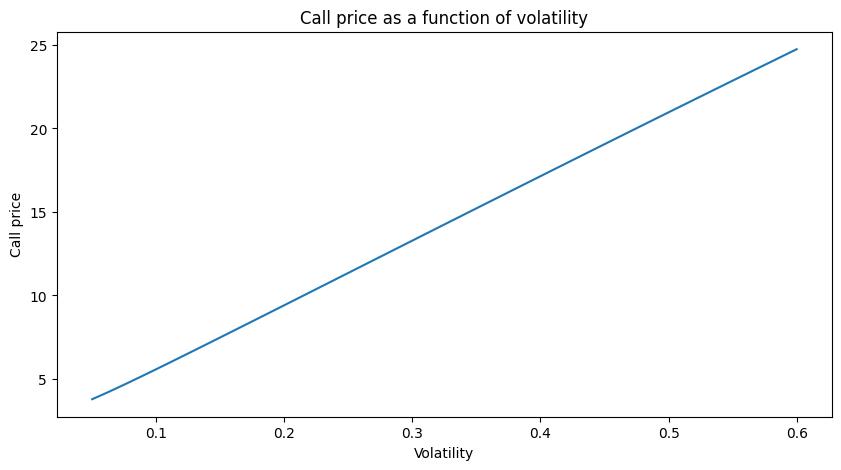

In [13]:
# Call price as a function of volatility
vols = np.linspace(0.05, 0.60, 56)
prices_vol = [bs_price(S0, K, T, r, v) for v in vols]

plt.figure(figsize=(10, 5))
plt.plot(vols, prices_vol)
plt.xlabel("Volatility")
plt.ylabel("Call price")
plt.title("Call price as a function of volatility")
plt.show()

### Interpretation

At the money, the delta of the call is 0.60: if the stock rises by 1, the call gains about 0.60. A trader who sold this call would buy 0.60 shares per option to hedge. The bump and reprice method gives the same delta, which is how risk systems compute Greeks for products without a closed formula.

The delta goes from 0 when the option is deep out of the money to 1 when it is deep in the money. Gamma and vega are highest around the strike: this is where the delta changes the fastest and where the option is the most sensitive to volatility. A 1 point increase in volatility adds 0.39 to the call price, and the price increases with volatility over the whole range: the option buyer is long volatility.

## Limitations

- Black-Scholes assumes a constant volatility, whereas market prices show a volatility smile: options with different strikes imply different volatilities.
- Interest rates are assumed constant and the stock pays no dividends.
- Log returns are normal in the model, while real returns have fatter tails and sudden jumps.
- The project covers European options only. Structured products such as autocalls depend on the whole path of the price and require Monte Carlo simulation of full paths (Step 3).